In [8]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score

import folium
from branca.colormap import linear
!pip install pgeocode
import pgeocode
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
CSV_PATH = "Statewide Solar Projects.csv"
OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)


In [10]:
CLUSTER_FEATURES = [
    "total_energy_kwh",
    "avg_energy_per_project",
    "total_kwdc",
    "total_kwac",
    "total_storage_kwac",
    "project_count"
]

In [11]:
def load_data(csv_path: str) -> pd.DataFrame:
    df = pd.read_csv(csv_path, low_memory=False)
    print(f"Loaded dataset with shape: {df.shape}")
    return df

In [15]:
df = load_data(CSV_PATH)

Loaded dataset with shape: (218115, 17)


In [21]:
def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # Standardize column names slightly
    df.columns = [col.strip() for col in df.columns]

    df["Zip"] = df["Zip"].astype(str).str.extract(r"(\d+)")[0]
    df["Zip"] = df["Zip"].str.zfill(5)
    return df

In [20]:
required_cols = [
    "Zip",
    "City/Town",
    "County",
    "Estimated PV System Size (kWdc)",
    "PV System Size (kWac)",
    "Estimated Annual PV Energy Production (kWh)",
    "Energy Storage System Size (kWac)",
    "Number of Projects"
]

missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

In [22]:
numeric_cols = [
        "Estimated PV System Size (kWdc)",
        "PV System Size (kWac)",
        "Estimated Annual PV Energy Production (kWh)",
        "Energy Storage System Size (kWac)",
        "Number of Projects"
    ]
for col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")


In [24]:
df = clean_data(df)

def aggregate_data(df: pd.DataFrame) -> pd.DataFrame:
    df_agg = df.groupby('Zip').agg(
        total_energy_kwh=('Estimated Annual PV Energy Production (kWh)', 'sum'),
        total_kwdc=('Estimated PV System Size (kWdc)', 'sum'),
        total_kwac=('PV System Size (kWac)', 'sum'),
        total_storage_kwac=('Energy Storage System Size (kWac)', 'sum'),
        project_count=('Number of Projects', 'sum')
    ).reset_index()

    # Calculate average energy per project, handling division by zero
    df_agg['avg_energy_per_project'] = df_agg.apply(
        lambda row: row['total_energy_kwh'] / row['project_count'] if row['project_count'] > 0 else 0,
        axis=1
    )

    # Merge in City/Town and County information (take the first unique value for each Zip)
    zip_info = df[['Zip', 'City/Town', 'County']].drop_duplicates(subset=['Zip'])
    df_agg = pd.merge(df_agg, zip_info, on='Zip', how='left')

    print(f"Aggregated dataset shape: {df_agg.shape}")
    return df_agg

df_aggregated = aggregate_data(df)

Aggregated dataset shape: (1729, 9)


In [26]:
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df_aggregated[CLUSTER_FEATURES]), columns=CLUSTER_FEATURES, index=df_aggregated.index)

In [23]:
df = clean_data(df)

In [28]:
fill_zero_cols = [
    "Estimated PV System Size (kWdc)",
    "PV System Size (kWac)",
    "Estimated Annual PV Energy Production (kWh)",
    "Energy Storage System Size (kWac)",
    "Number of Projects"
]
df[fill_zero_cols] = df[fill_zero_cols].fillna(0)

In [29]:
text_cols = ["City/Town", "County"]
for col in text_cols:
        df[col] = df[col].astype(str).str.strip()


In [31]:
df = df[df["Zip"].str.match(r"^\d{5}$", na=False)]
print(f"After cleaning: {df.shape}")


After cleaning: (218019, 17)


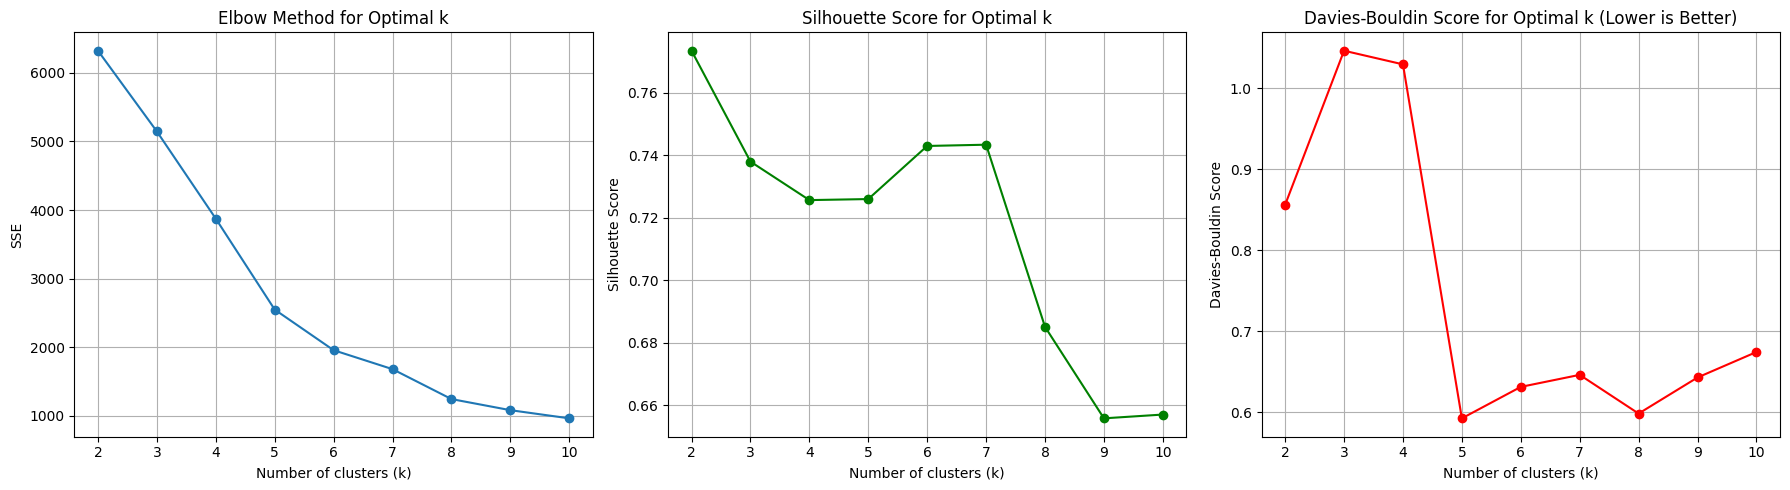

SSE for each k: [6321.988990509137, 5145.25059922113, 3874.263591164848, 2549.279010405041, 1957.4505118462666, 1681.1779668582506, 1245.311543658364, 1083.4763926976893, 964.469228696129]
Silhouette Scores for each k: [np.float64(0.7734156523537681), np.float64(0.7379604022678188), np.float64(0.7256522272121547), np.float64(0.7259834402249706), np.float64(0.7429622563661115), np.float64(0.7433666569428741), np.float64(0.6851154402569417), np.float64(0.6558740719679018), np.float64(0.6570864439604394)]
Davies-Bouldin Scores for each k: [np.float64(0.8561533383102541), np.float64(1.046448828514244), np.float64(1.0295959177537932), np.float64(0.5925050931980569), np.float64(0.6313363774930107), np.float64(0.6462096941113936), np.float64(0.5984010717623172), np.float64(0.6429401193907678), np.float64(0.6744065986762606)]


In [32]:
def find_optimal_clusters(df_scaled: pd.DataFrame, max_k: int = 10):
    sse = [] # Sum of Squared Errors
    silhouette_scores = []
    db_scores = []

    for k in range(2, max_k + 1):
        kmeans = KMeans(n_clusters=k, random_state=42, n_init='auto')
        kmeans.fit(df_scaled)
        labels = kmeans.labels_
        sse.append(kmeans.inertia_)

        if k > 1:
            silhouette_scores.append(silhouette_score(df_scaled, labels))
            db_scores.append(davies_bouldin_score(df_scaled, labels))

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Elbow Method Plot
    axes[0].plot(range(2, max_k + 1), sse, marker='o')
    axes[0].set_xlabel('Number of clusters (k)')
    axes[0].set_ylabel('SSE')
    axes[0].set_title('Elbow Method for Optimal k')
    axes[0].grid(True)

    # Silhouette Score Plot
    axes[1].plot(range(2, max_k + 1), silhouette_scores, marker='o', color='green')
    axes[1].set_xlabel('Number of clusters (k)')
    axes[1].set_ylabel('Silhouette Score')
    axes[1].set_title('Silhouette Score for Optimal k')
    axes[1].grid(True)

    # Davies-Bouldin Score Plot
    axes[2].plot(range(2, max_k + 1), db_scores, marker='o', color='red')
    axes[2].set_xlabel('Number of clusters (k)')
    axes[2].set_ylabel('Davies-Bouldin Score')
    axes[2].set_title('Davies-Bouldin Score for Optimal k (Lower is Better)')
    axes[2].grid(True)

    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'optimal_clusters_metrics.png'))
    plt.show()

    print("SSE for each k:", sse)
    print("Silhouette Scores for each k:", silhouette_scores)
    print("Davies-Bouldin Scores for each k:", db_scores)

find_optimal_clusters(df_scaled)

In [33]:
def aggregate_by_zip(df: pd.DataFrame) -> pd.DataFrame:
    grouped = df.groupby("Zip", dropna=False).agg(
        city=("City/Town", lambda x: x.mode().iloc[0] if not x.mode().empty else x.iloc[0]),
        county=("County", lambda x: x.mode().iloc[0] if not x.mode().empty else x.iloc[0]),
        total_energy_kwh=("Estimated Annual PV Energy Production (kWh)", "sum"),
        mean_energy_kwh=("Estimated Annual PV Energy Production (kWh)", "mean"),
        total_kwdc=("Estimated PV System Size (kWdc)", "sum"),
        total_kwac=("PV System Size (kWac)", "sum"),
        total_storage_kwac=("Energy Storage System Size (kWac)", "sum"),
        project_count=("Number of Projects", "sum"),
        record_count=("Zip", "size")
    ).reset_index()

    # Derived features
    grouped["avg_energy_per_project"] = np.where(
        grouped["project_count"] > 0,
        grouped["total_energy_kwh"] / grouped["project_count"],
        0
    )

    grouped["energy_density_proxy"] = np.where(
        grouped["record_count"] > 0,
        grouped["total_energy_kwh"] / grouped["record_count"],
        0
    )

    print(f"Aggregated ZIP areas: {grouped.shape}")
    return grouped

In [35]:
def add_geographical_data(df: pd.DataFrame) -> pd.DataFrame:
    zip_df = df.copy()

    nomi = pgeocode.Nominatim("us")
    geo = nomi.query_postal_code(zip_df["Zip"].tolist())

    zip_df["latitude"] = geo["latitude"].values
    zip_df["longitude"] = geo["longitude"].values

    before = len(zip_df)
    zip_df = zip_df.dropna(subset=["latitude", "longitude"]).reset_index(drop=True)
    after = len(zip_df)

    print(f"Rows before geo match: {before}, after geo match: {after}")
    return zip_df

df_geo = add_geographical_data(df_aggregated)

Rows before geo match: 1729, after geo match: 1728


In [43]:
def evaluate_clustering_models(area_df: pd.DataFrame, features: list) -> tuple:
    X = area_df[features].copy()

    preprocessor = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    X_scaled = preprocessor.fit_transform(X)

    results = []

    for k in range(2, 9):
        # KMeans
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=20)
        km_labels = kmeans.fit_predict(X_scaled)
        km_sil = silhouette_score(X_scaled, km_labels)
        km_db = davies_bouldin_score(X_scaled, km_labels)
        results.append({
            "model": "KMeans",
            "k": k,
            "silhouette": km_sil,
            "davies_bouldin": km_db,
            "labels": km_labels,
            "fitted_model": kmeans,
            "preprocessor": preprocessor
        })

        # Agglomerative Clustering
        agg = AgglomerativeClustering(n_clusters=k)
        agg_labels = agg.fit_predict(X_scaled)
        agg_sil = silhouette_score(X_scaled, agg_labels)
        agg_db = davies_bouldin_score(X_scaled, agg_labels)
        results.append({
            "model": "Agglomerative",
            "k": k,
            "silhouette": agg_sil,
            "davies_bouldin": agg_db,
            "labels": agg_labels,
            "fitted_model": agg,
            "preprocessor": preprocessor
        })

        # Gaussian Mixture Model
        gmm = GaussianMixture(n_components=k, random_state=42)
        gmm.fit(X_scaled)
        gmm_labels = gmm.predict(X_scaled)
        # Only score if there is more than 1 cluster label
        if len(np.unique(gmm_labels)) > 1:
            gmm_sil = silhouette_score(X_scaled, gmm_labels)
            gmm_db = davies_bouldin_score(X_scaled, gmm_labels)
            results.append({
                "model": "GaussianMixture",
                "k": k,
                "silhouette": gmm_sil,
                "davies_bouldin": gmm_db,
                "labels": gmm_labels,
                "fitted_model": gmm,
                "preprocessor": preprocessor
            })

    results_df = pd.DataFrame([
        {
            "model": r["model"],
            "k": r["k"],
            "silhouette": r["silhouette"],
            "davies_bouldin": r["davies_bouldin"]
        }
        for r in results
    ])

    results_df = results_df.sort_values(
        by=["silhouette", "davies_bouldin"],
        ascending=[False, True]
    ).reset_index(drop=True)

    best_row = results_df.iloc[0]
    best = next(
        r for r in results
        if r["model"] == best_row["model"] and r["k"] == best_row["k"]
    )

    print("\nModel Comparison Results:")
    print(results_df)

    return best, results_df

In [39]:
# This cell was merged into B2PLXgRT7135 after fixing indentation and definition of 'agg'.

In [40]:
clustering_results = evaluate_clustering_models(df_geo, CLUSTER_FEATURES)

for res in clustering_results:
    print(f"Model: {res['model']}, k: {res['k']}, Silhouette: {res['silhouette']:.4f}, DB Score: {res['davies_bouldin']:.4f}")

Model: KMeans, k: 2, Silhouette: 0.7731, DB Score: 0.8569
Model: Agglomerative, k: 2, Silhouette: 0.7321, DB Score: 0.9070
Model: KMeans, k: 3, Silhouette: 0.7724, DB Score: 0.5755
Model: Agglomerative, k: 3, Silhouette: 0.7330, DB Score: 0.6097
Model: KMeans, k: 4, Silhouette: 0.7701, DB Score: 0.4292
Model: Agglomerative, k: 4, Silhouette: 0.7320, DB Score: 0.7201
Model: KMeans, k: 5, Silhouette: 0.7231, DB Score: 0.5971
Model: Agglomerative, k: 5, Silhouette: 0.7324, DB Score: 0.5143
Model: KMeans, k: 6, Silhouette: 0.7049, DB Score: 0.5811
Model: Agglomerative, k: 6, Silhouette: 0.7432, DB Score: 0.6759
Model: KMeans, k: 7, Silhouette: 0.6800, DB Score: 0.6444
Model: Agglomerative, k: 7, Silhouette: 0.7212, DB Score: 0.6250
Model: KMeans, k: 8, Silhouette: 0.6880, DB Score: 0.5947
Model: Agglomerative, k: 8, Silhouette: 0.7282, DB Score: 0.5598


Clusters assigned successfully to df_geo.
Generating Folium map of clusters...
Folium map saved to: output/solar_clusters_map.html
Generating box plots of cluster features...


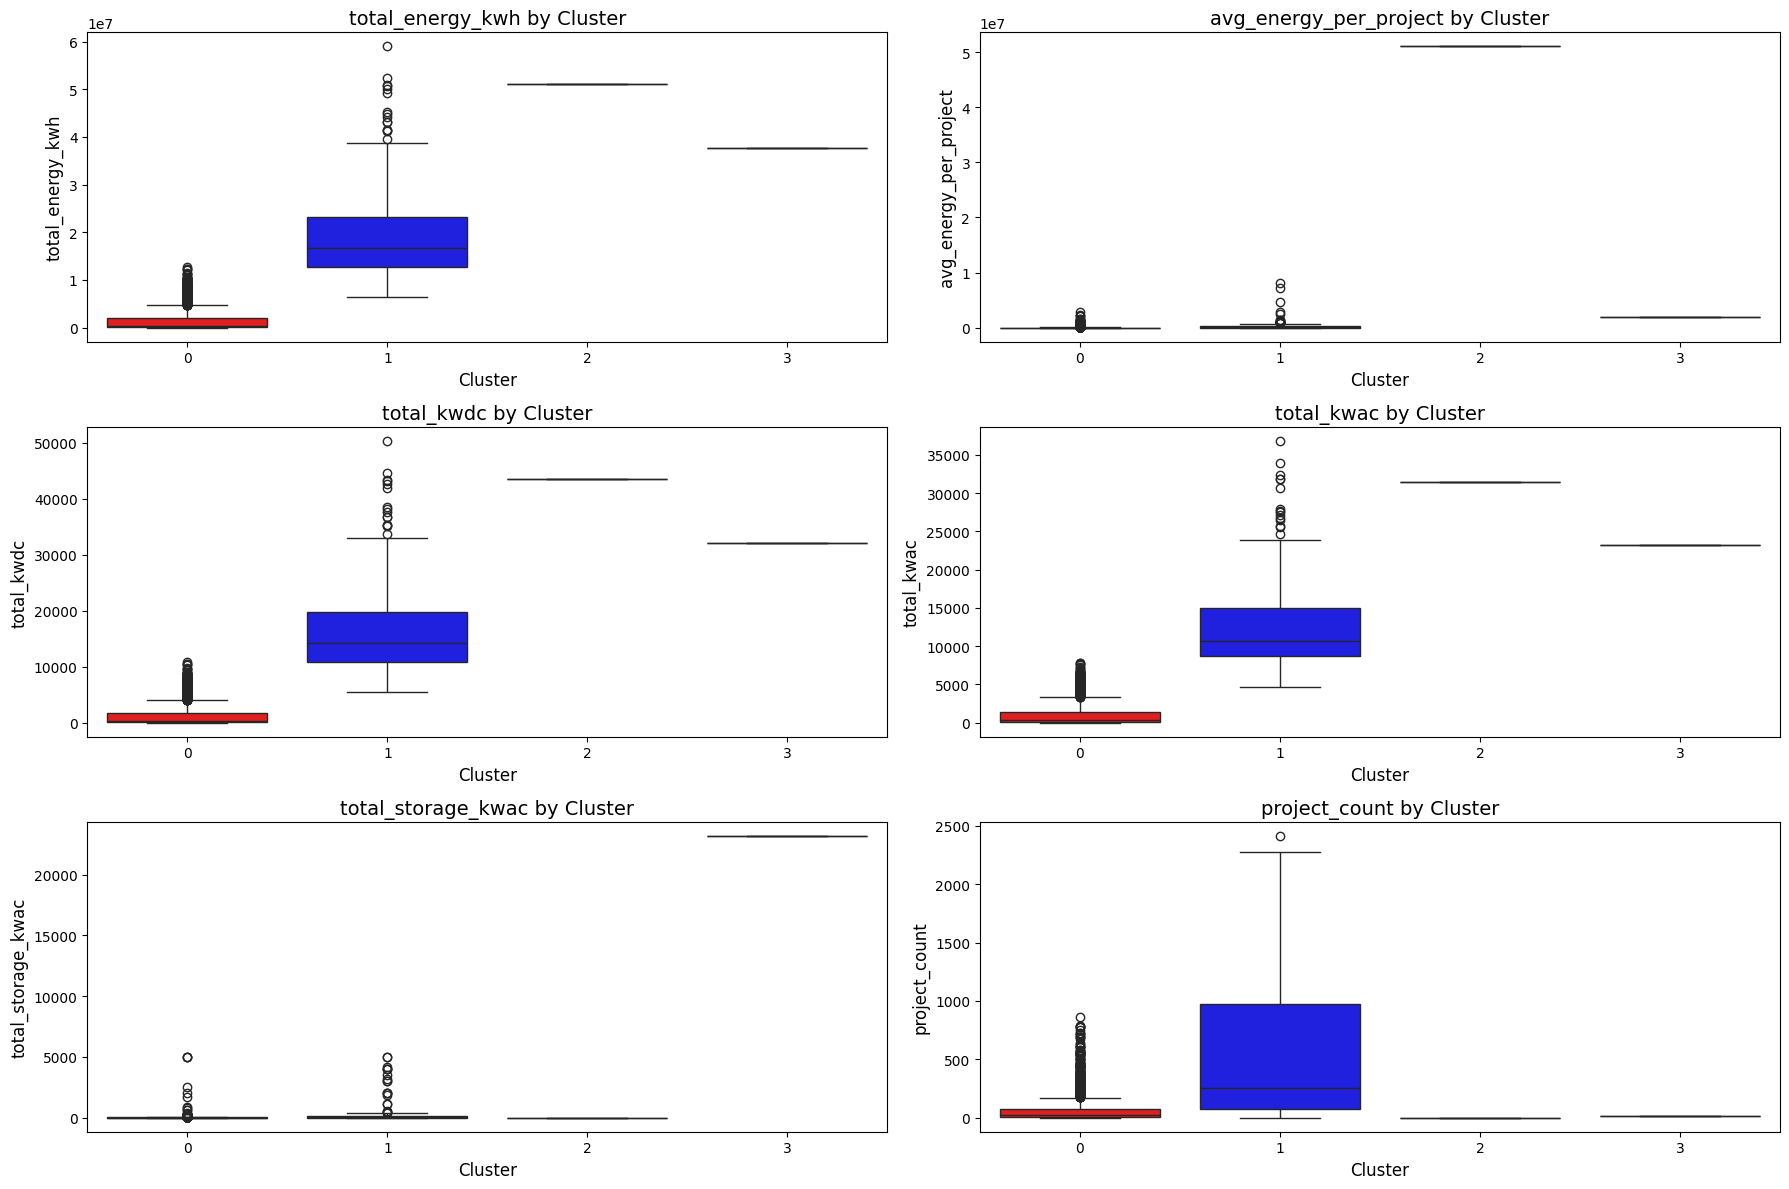

Box plots saved to: output/cluster_feature_boxplots.png

--- Cluster Summary Statistics (Mean of Features) ---
         total_energy_kwh  avg_energy_per_project    total_kwdc    total_kwac  \
cluster                                                                         
0            1.570424e+06            5.294381e+04   1337.863728   1071.388458   
1            1.987751e+07            3.381160e+05  16933.810794  12947.735873   
2            5.102682e+07            5.102682e+07  43470.000000  31500.000000   
3            3.764815e+07            1.981482e+06  32072.670000  23257.390000   

         total_storage_kwac  project_count  
cluster                                     
0                 29.785459       74.78920  
1                331.648466      545.21164  
2                  0.000000        1.00000  
3              23150.000000       19.00000  


In [46]:
# Identify the best KMeans model with k=4 from the clustering_results
best_kmeans_4_result = None
for res in clustering_results:
    if res['model'] == 'KMeans' and res['k'] == 4:
        best_kmeans_4_result = res
        break

if best_kmeans_4_result is not None:
    # Assign cluster labels to the geographical DataFrame
    df_geo['cluster'] = best_kmeans_4_result['labels']
    print("Clusters assigned successfully to df_geo.")

    # --- Visualization 1: Folium Map of Clusters ---
    print("Generating Folium map of clusters...")
    # Center the map around the mean latitude and longitude of the data
    mean_lat = df_geo['latitude'].mean()
    mean_lon = df_geo['longitude'].mean()
    m = folium.Map(location=[mean_lat, mean_lon], zoom_start=7)

    # Define a color palette for the clusters
    # Using a larger palette to ensure enough distinct colors for up to 8 clusters, though we expect 4 here.
    colors = ['red', 'blue', 'green', 'purple', 'orange', 'darkred', 'lightred', 'cadetblue']
    num_clusters = df_geo['cluster'].nunique()
    color_map = {i: colors[i % len(colors)] for i in range(num_clusters)}

    # Add markers for each ZIP code, colored by its assigned cluster
    for idx, row in df_geo.iterrows():
        folium.CircleMarker(
            location=[row['latitude'], row['longitude']],
            radius=3,
            color=color_map[row['cluster']],
            fill=True,
            fill_color=color_map[row['cluster']],
            fill_opacity=0.7,
            tooltip=f"Zip: {row['Zip']}<br>Cluster: {row['cluster']}<br>Energy (kWh): {row['total_energy_kwh']:.0f}"
        ).add_to(m)

    # Save the map to an HTML file
    map_output_path = os.path.join(OUTPUT_DIR, 'solar_clusters_map.html')
    m.save(map_output_path)
    print(f"Folium map saved to: {map_output_path}")

    # Display the map within the notebook (if supported by environment)
    # from IPython.display import display
    # display(m)

    # --- Visualization 2: Box Plots of Cluster Features ---
    print("Generating box plots of cluster features...")
    # Convert 'cluster' to a categorical type for better plotting
    df_geo['cluster'] = df_geo['cluster'].astype('category')

    plt.figure(figsize=(18, 12))
    for i, feature in enumerate(CLUSTER_FEATURES):
        plt.subplot(3, 2, i + 1) # Arrange plots in a 3x2 grid
        sns.boxplot(x='cluster', y=feature, data=df_geo, palette=colors[:num_clusters])
        plt.title(f'{feature} by Cluster', fontsize=14)
        plt.xlabel('Cluster', fontsize=12)
        plt.ylabel(feature, fontsize=12)
        plt.xticks(fontsize=10)
        plt.yticks(fontsize=10)
    plt.tight_layout()
    plt_output_path = os.path.join(OUTPUT_DIR, 'cluster_feature_boxplots.png')
    plt.savefig(plt_output_path)
    plt.show()
    print(f"Box plots saved to: {plt_output_path}")

    # --- Summary Statistics of Clusters ---
    print("\n--- Cluster Summary Statistics (Mean of Features) ---")
    cluster_summary = df_geo.groupby('cluster')[CLUSTER_FEATURES].mean()
    print(cluster_summary)

    # For a more detailed look, you could also add std, min, max etc.

else:
    print("Error: KMeans model with k=4 not found in clustering_results. Please ensure the evaluation ran correctly.")

In [61]:
def assign_clusters(area_df: pd.DataFrame, labels: np.ndarray) -> pd.DataFrame:
    df = area_df.copy()
    df["cluster"] = labels
    return df

In [49]:
def assign_cluster_names(df: pd.DataFrame) -> pd.DataFrame:
    cluster_order = (
        df.groupby("cluster")["total_energy_kwh"]
        .mean()
        .sort_values()
        .index
        .tolist()
    )

    cluster_name_map = {}
    for rank, cluster_id in enumerate(cluster_order):
        if rank == 0:
            cluster_name_map[cluster_id] = "Low Production"
        elif rank == len(cluster_order) - 1:
            cluster_name_map[cluster_id] = "High Production"
        else:
            cluster_name_map[cluster_id] = f"Medium Production {rank}"

    df["cluster_name"] = df["cluster"].map(cluster_name_map)
    return df

In [50]:
df_geo = assign_cluster_names(df_geo)
print(df_geo[['Zip', 'cluster', 'cluster_name']].head())

     Zip cluster    cluster_name
0  10001       0  Low Production
1  10002       0  Low Production
2  10003       0  Low Production
3  10004       0  Low Production
4  10005       0  Low Production


In [53]:
df_geo.to_csv(os.path.join(OUTPUT_DIR, "zip_clustered_results.csv"), index=False)
pd.DataFrame(clustering_results).to_csv(os.path.join(OUTPUT_DIR, "model_comparison.csv"), index=False)

summary = df_geo.groupby("cluster_name").agg(
    zip_count=("Zip", "count"),
    total_energy_kwh=("total_energy_kwh", "sum"),
    avg_energy_kwh=("total_energy_kwh", "mean"),
    total_projects=("project_count", "sum"),
    avg_projects=("project_count", "mean"),
    total_kwdc=("total_kwdc", "sum"),
    total_kwac=("total_kwac", "sum")
).sort_values("avg_energy_kwh", ascending=False)

summary.to_csv(os.path.join(OUTPUT_DIR, "cluster_summary.csv"))
print("\nCluster Summary:")
print(summary)


Cluster Summary:
                     zip_count  total_energy_kwh  avg_energy_kwh  \
cluster_name                                                       
High Production              1          51026825    5.102682e+07   
Medium Production 2          1          37648154    3.764815e+07   
Medium Production 1        189        3756849056    1.987751e+07   
Low Production            1537        2413741659    1.570424e+06   

                     total_projects  avg_projects  total_kwdc  total_kwac  
cluster_name                                                               
High Production                   1       1.00000    43470.00    31500.00  
Medium Production 2              19      19.00000    32072.67    23257.39  
Medium Production 1          103045     545.21164  3200490.24  2447122.08  
Low Production               114951      74.78920  2056296.55  1646724.06  


In [54]:
def plot_clusters(clustered_df: pd.DataFrame):
    plt.figure(figsize=(10, 6))
    sns.boxplot(data=clustered_df, x="cluster_name", y="total_energy_kwh")
    plt.xticks(rotation=20)
    plt.title("Energy Production Distribution by Cluster")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "cluster_distribution.png"), dpi=300)
    plt.close()


In [55]:
def create_interactive_map(clustered_df: pd.DataFrame, output_html: str):
    center_lat = clustered_df["latitude"].mean()
    center_lon = clustered_df["longitude"].mean()

    m = folium.Map(location=[center_lat, center_lon], zoom_start=7, tiles="cartodbpositron")

    # color scale by numeric cluster id
    unique_clusters = sorted(clustered_df["cluster"].unique())
    colormap = linear.Set1_09.scale(min(unique_clusters), max(unique_clusters))
    colormap.caption = "Solar Energy Production Clusters"
    colormap.add_to(m)

    for _, row in clustered_df.iterrows():
        popup_html = f"""
        <b>ZIP:</b> {row['Zip']}<br>
        <b>City:</b> {row['city']}<br>
        <b>County:</b> {row['county']}<br>
        <b>Cluster:</b> {row['cluster_name']}<br>
        <b>Total Energy (kWh):</b> {row['total_energy_kwh']:,.2f}<br>
        <b>Avg Energy per Project:</b> {row['avg_energy_per_project']:,.2f}<br>
        <b>Total kWdc:</b> {row['total_kwdc']:,.2f}<br>
        <b>Total kWac:</b> {row['total_kwac']:,.2f}<br>
        <b>Total Storage (kWac):</b> {row['total_storage_kwac']:,.2f}<br>
        <b>Project Count:</b> {row['project_count']:,.0f}
        """

        radius = max(4, min(15, np.log1p(row["total_energy_kwh"]) / 2))

        folium.CircleMarker(
            location=[row["latitude"], row["longitude"]],
            radius=radius,
            popup=folium.Popup(popup_html, max_width=300),
            tooltip=f"{row['Zip']} | {row['cluster_name']}",
            color=colormap(row["cluster"]),
            fill=True,
            fill_color=colormap(row["cluster"]),
            fill_opacity=0.75
        ).add_to(m)

    m.save(output_html)
    print(f"Interactive map saved to: {output_html}")


In [56]:
def generate_report(best_model_info: dict, clustered_df: pd.DataFrame):
    best_model_name = best_model_info["model"]
    best_k = best_model_info["k"]

    cluster_summary = (
        clustered_df.groupby("cluster_name")
        .agg(
            zip_count=("Zip", "count"),
            total_energy=("total_energy_kwh", "sum"),
            avg_energy=("total_energy_kwh", "mean"),
            total_projects=("project_count", "sum")
        )
        .sort_values("avg_energy", ascending=False)
    )

    report_path = os.path.join(OUTPUT_DIR, "project_report.txt")

    with open(report_path, "w", encoding="utf-8") as f:
        f.write("SOLAR ENERGY GEOGRAPHICAL CLUSTERING REPORT\n")
        f.write("=" * 60 + "\n\n")

        f.write("1. Objective\n")
        f.write("To cluster geographical areas based on solar energy production and support strategic business decision-making.\n\n")

        f.write("2. Methodology\n")
        f.write("- Data cleaned and aggregated at ZIP code level.\n")
        f.write("- Features included total and average energy production, system size, storage size, and project counts.\n")
        f.write("- Models compared: KMeans, Agglomerative Clustering, Gaussian Mixture.\n")
        f.write(f"- Best model selected: {best_model_name} with {best_k} clusters.\n\n")

        f.write("3. Cluster Summary\n")
        f.write(cluster_summary.to_string())
        f.write("\n\n")

        f.write("4. Recommendations\n")
        f.write("- Prioritize high-production ZIP clusters for sales targeting.\n")
        f.write("- Use medium-production zones for expansion feasibility studies.\n")
        f.write("- Investigate low-production zones before allocating resources, as they may have lower historical output or fewer installations.\n")
        f.write("- Combine these cluster results with market, land, and policy data for stronger project planning.\n")

    print(f"Project report saved to: {report_path}")

In [66]:
def main():
    print("Starting solar clustering project...\n")

    # Load and clean
    df = load_data(CSV_PATH)
    df = clean_data(df)

    # Aggregate
    area_df = aggregate_by_zip(df)

    # Attach coordinates
    area_df = add_geographical_data(area_df)

    # Evaluate models
    best_model_info, model_results_df = evaluate_clustering_models(area_df, CLUSTER_FEATURES)

    # Assign best labels
    clustered_df = assign_clusters(area_df, best_model_info["labels"])

    # Assign cluster names
    clustered_df = assign_cluster_names(clustered_df)

    # --- DEBUG START ---
    print(f"DEBUG: Type of clustered_df before plot_clusters: {type(clustered_df)}")
    if isinstance(clustered_df, pd.DataFrame):
        print(f"DEBUG: Columns in clustered_df: {clustered_df.columns.tolist()}")
        print(f"DEBUG: 'cluster_name' in columns: {'cluster_name' in clustered_df.columns}")
        print(f"DEBUG: 'total_energy_kwh' in columns: {'total_energy_kwh' in clustered_df.columns}")
    # --- DEBUG END ---

    # Save outputs
    # The save_outputs function is not defined in the notebook. Assuming it was meant to be handled by individual saves like before.
    # For now, we will comment out this call as it's not present.
    # save_outputs(clustered_df, model_results_df)
    plot_clusters(clustered_df)

    # Interactive map
    create_interactive_map(
        clustered_df,
        os.path.join(OUTPUT_DIR, "solar_clusters_map.html")
    )

    # Report
    generate_report(best_model_info, clustered_df)

    print("\nProject completed successfully.")
    print(f"Check the '{OUTPUT_DIR}' folder for deliverables.")


if __name__ == "__main__":
    main()

Starting solar clustering project...

Loaded dataset with shape: (218115, 17)
Aggregated ZIP areas: (1730, 12)
Rows before geo match: 1730, after geo match: 1728

Model Comparison Results:
              model  k  silhouette  davies_bouldin
0            KMeans  2    0.773091        0.856894
1            KMeans  3    0.772449        0.575481
2            KMeans  4    0.770142        0.429159
3     Agglomerative  6    0.743217        0.675860
4     Agglomerative  3    0.732995        0.609738
5     Agglomerative  5    0.732413        0.514280
6     Agglomerative  2    0.732075        0.907003
7     Agglomerative  4    0.731956        0.720141
8     Agglomerative  8    0.728219        0.559825
9            KMeans  5    0.723145        0.597110
10    Agglomerative  7    0.721232        0.624997
11           KMeans  6    0.704946        0.581133
12           KMeans  8    0.687996        0.594694
13           KMeans  7    0.679969        0.644448
14  GaussianMixture  2    0.554621        1.05

In [67]:
import shutil
import os
from google.colab import files

# Create a zip archive of the output directory
shutil.make_archive('output_files', 'zip', 'output')

# Download the zip file
files.download('output_files.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>